In [ ]:
 #importer les outils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor


In [ ]:
#charger les données (FRED)
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"
df = pd.read_csv(url)
df = df.rename(columns={df.columns[0]: "date", df.columns[1]: "sp500"})
df["date"] = pd.to_datetime(df["date"])
df["sp500"] = pd.to_numeric(df["sp500"], errors="coerce")  # les valeurs manquantes deviennent NaN
df = df.set_index("date")
print("Dimensions :", df.shape)
df.head()

Dimensions : (2609, 1)


,sp500
date,
2016-11-07,2131.52
2016-11-08,2139.56
2016-11-09,2163.26
2016-11-10,2167.48
2016-11-11,2164.45


Dimensions : (2609, 1)


,sp500
date,
2016-11-07,2131.52
2016-11-08,2139.56
2016-11-09,2163.26
2016-11-10,2167.48
2016-11-11,2164.45


In [ ]:
#nettoyer et créer les variables
df = df.dropna()
df["rendement"] = np.log(df["sp500"] / df["sp500"].shift(1))  # rendement logarithmique
df["vol20"] = df["rendement"].rolling(20).std()               # volatilité sur 20 jours
df = df.dropna()
print("Observations après nettoyage :", len(df))
df.describe()

Observations après nettoyage : 2493


,sp500,rendement,vol20
count,2493.000000,2493.000000,2493.000000
mean,4230.272487,0.000483,0.009446
std,1510.450072,0.011493,0.006574
min,2212.230000,-0.127652,0.002069
25%,2878.200000,-0.003794,0.005710
50%,4017.820000,0.000800,0.007746
75%,5222.680000,0.005897,0.011355
max,7818.930000,0.090895,0.061669


Observations après nettoyage : 2493


,sp500,rendement,vol20
count,2493.000000,2493.000000,2493.000000
mean,4230.272487,0.000483,0.009446
std,1510.450072,0.011493,0.006574
min,2212.230000,-0.127652,0.002069
25%,2878.200000,-0.003794,0.005710
50%,4017.820000,0.000800,0.007746
75%,5222.680000,0.005897,0.011355
max,7818.930000,0.090895,0.061669


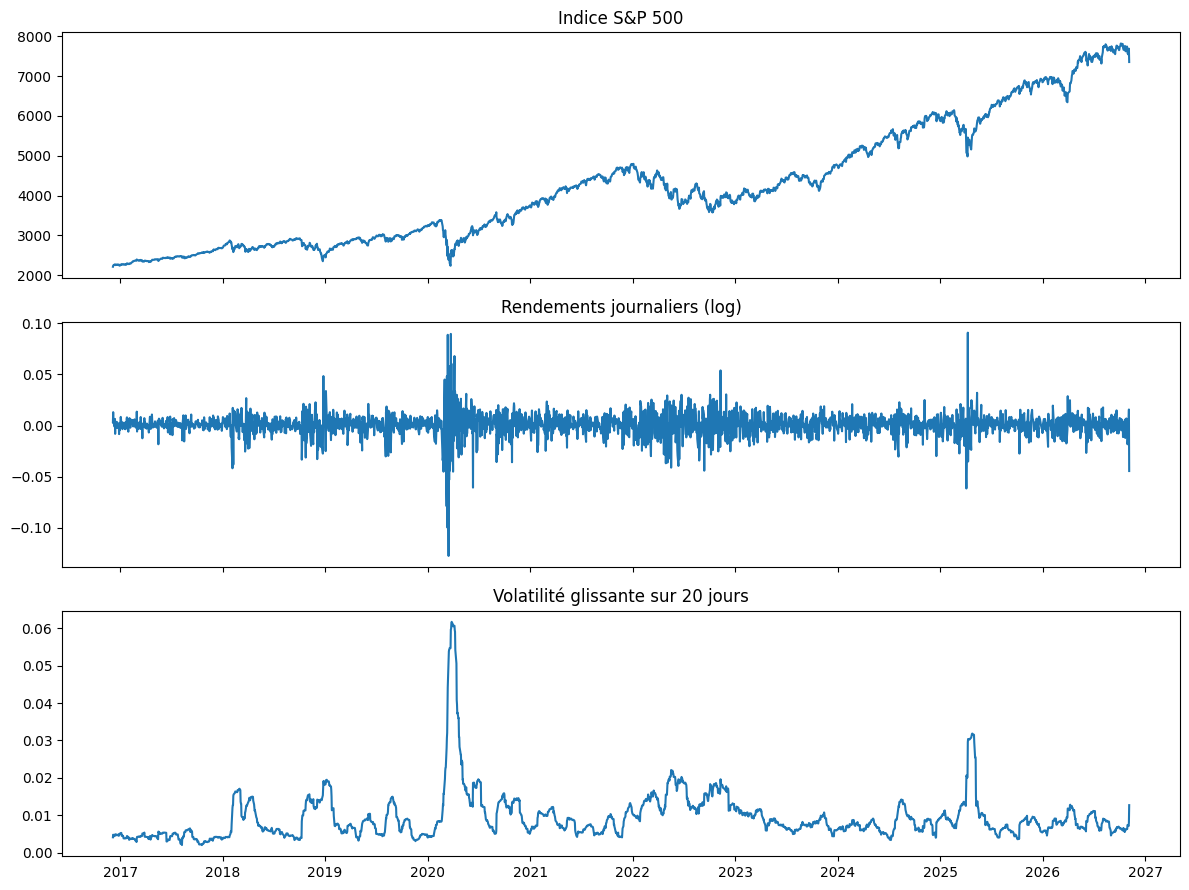

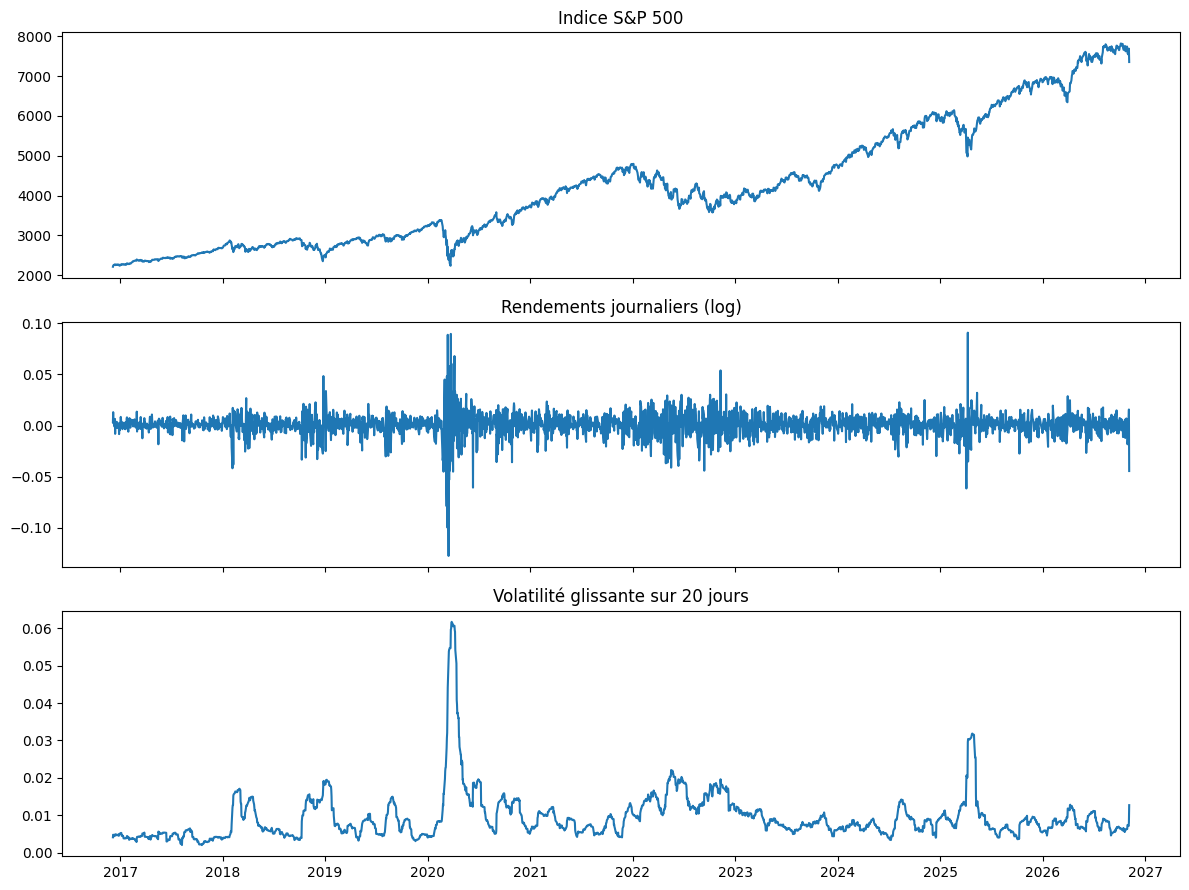

In [ ]:
 #visualiser les données
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(df.index, df["sp500"]);      axes[0].set_title("Indice S&P 500")
axes[1].plot(df.index, df["rendement"]);  axes[1].set_title("Rendements journaliers (log)")
axes[2].plot(df.index, df["vol20"]);      axes[2].set_title("Volatilité glissante sur 20 jours")
plt.tight_layout()
plt.show()


In [ ]:
#préparer les variables
variables = ["rendement", "vol20"]
X = StandardScaler().fit_transform(df[variables])
print(X.shape)

(2493, 2)
(2493, 2)


In [ ]:
#détecter les anomalies avec deux modèles
# On suppose environ 1 % de journées atypiques
iso = IsolationForest(contamination=0.01, random_state=42)
df["anom_iso"] = iso.fit_predict(X) == -1

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01)
df["anom_lof"] = lof.fit_predict(X) == -1

print("Anomalies Isolation Forest :", df["anom_iso"].sum())
print("Anomalies LOF              :", df["anom_lof"].sum())
print("Anomalies communes         :", (df["anom_iso"] & df["anom_lof"]).sum())

Anomalies Isolation Forest : 25
Anomalies LOF              : 25
Anomalies communes         : 8
Anomalies Isolation Forest : 25
Anomalies LOF              : 25
Anomalies communes         : 8


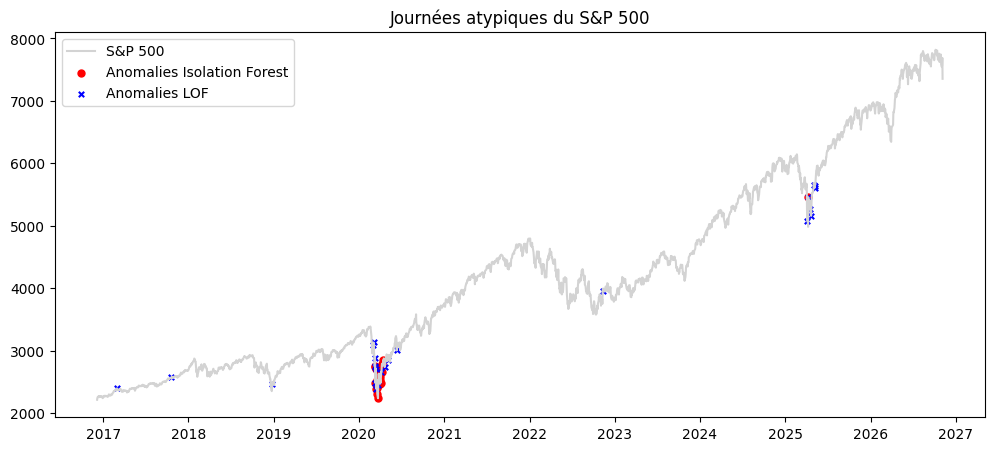

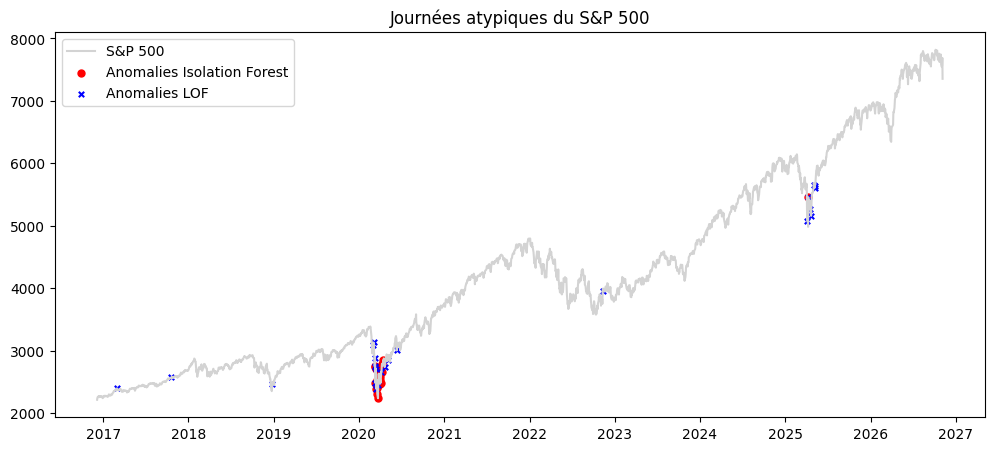

In [ ]:
#frise chronologique des anomalies
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df["sp500"], color="lightgray", label="S&P 500")
ax.scatter(df.index[df["anom_iso"]], df["sp500"][df["anom_iso"]],
           color="red", s=25, label="Anomalies Isolation Forest")
ax.scatter(df.index[df["anom_lof"]], df["sp500"][df["anom_lof"]],
           color="blue", s=15, marker="x", label="Anomalies LOF")
ax.set_title("Journées atypiques du S&P 500")
ax.legend()
plt.show()

In [ ]:
#les 10 journées les plus atypiques
top = df[df["anom_iso"]].copy()
top["abs_rend"] = top["rendement"].abs()
top = top.sort_values("abs_rend", ascending=False).head(10)
top[["sp500", "rendement", "vol20"]]

,sp500,rendement,vol20
date,,,
2020-03-16,2386.13,-0.127652,0.051097
2020-03-12,2480.64,-0.099945,0.037497
2025-04-09,5456.90,0.090895,0.029548
2020-03-24,2447.33,0.089683,0.059617
2020-03-13,2711.02,0.088808,0.044121
2020-03-09,2746.56,-0.079010,0.028028
2020-04-06,2663.68,0.067968,0.060617
2020-03-26,2630.07,0.060544,0.061349
2020-03-17,2529.19,0.058226,0.053769


,sp500,rendement,vol20
date,,,
2020-03-16,2386.13,-0.127652,0.051097
2020-03-12,2480.64,-0.099945,0.037497
2025-04-09,5456.90,0.090895,0.029548
2020-03-24,2447.33,0.089683,0.059617
2020-03-13,2711.02,0.088808,0.044121
2020-03-09,2746.56,-0.079010,0.028028
2020-04-06,2663.68,0.067968,0.060617
2020-03-26,2630.07,0.060544,0.061349
2020-03-17,2529.19,0.058226,0.053769


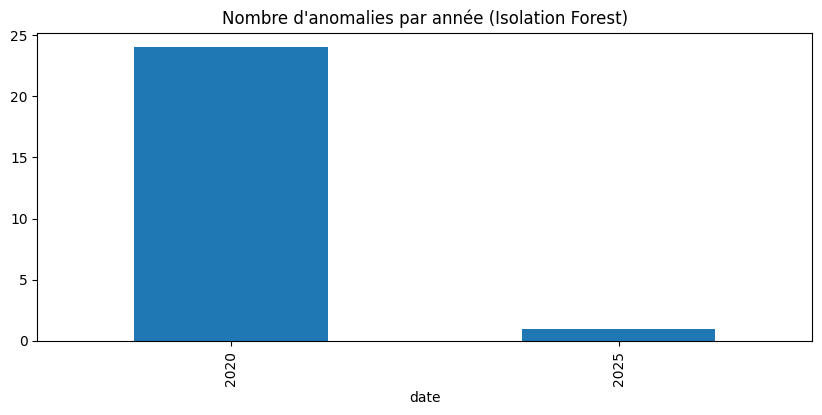

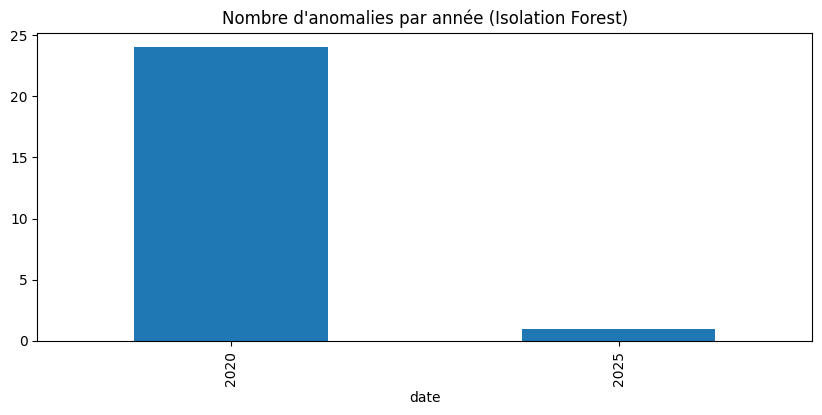

In [ ]:
#comparer avec les événements connus
# Concentration des anomalies par année
anomalies_par_an = df[df["anom_iso"]].groupby(df[df["anom_iso"]].index.year).size()
anomalies_par_an.plot(kind="bar", figsize=(10, 4), title="Nombre d'anomalies par année (Isolation Forest)")
plt.show()

## Conclusion

**Objectif.** Identifier les journées statistiquement atypiques du S&P 500 à partir du rendement journalier et de la volatilité sur 20 jours, avec deux méthodes non supervisées : Isolation Forest et LOF.

**Résultats.**
- Les deux modèles ont été réglés pour détecter environ 1 % des journées comme anomalies. Ils repèrent un nombre voisin de journées, dont une partie seulement est commune aux deux méthodes (voir cellule 6). Ils ne définissent donc pas exactement les mêmes anomalies, mais ils se recoupent sur les cas les plus extrêmes.
- Les journées les plus atypiques (cellule 8) sont celles où le rendement est très fortement positif ou négatif, avec une volatilité élevée. Elles se concentrent surtout en mars 2020, au moment de la crise du Covid-19, où le marché a connu des chutes et des rebonds très brutaux.
- Le graphique par année (cellule 9) montre que les anomalies ne sont pas réparties au hasard : elles se regroupent pendant des périodes de stress sur les marchés plutôt que d'apparaître de façon isolée.

**Interprétation.** Les modèles détectent surtout les journées de forte variation et de forte volatilité. Les périodes repérées correspondent à des épisodes de marché connus, ce qui rend la méthode crédible, sans toutefois la valider de façon formelle.

**Limites.**
- Il n'y a pas d'étiquettes : on ne peut pas calculer de score de performance. La comparaison avec les événements connus reste qualitative et subjective.
- Le taux de 1 % d'anomalies (`contamination=0.01`) est un choix arbitraire. Un autre seuil donnerait d'autres résultats.
- Les données FRED ne couvrent que les dix dernières années, ce qui limite les conclusions.
- Seules deux variables sont utilisées (rendement et volatilité). D'autres variables, comme le volume, pourraient changer les résultats.

**Pistes d'amélioration.** Tester d'autres valeurs de `contamination`, ajouter des variables, et comparer avec un indice de volatilité comme le VIX.

